In [1]:
# ============ 셀 1: 설정 (L6B: L6A 모델 5개 → Muon 파인튜닝) ============
import os, json, time, math, random, glob, shutil
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F

assert torch.cuda.is_available(), "GPU가 꺼져 있어요. Settings → Accelerator → GPU T4 로 바꾸세요."
DEV = 'cuda'

OUT  = '/kaggle/working/exp_l6_finetune'
DATA = '/tmp/llm_data'
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)

CFG = dict(
    seed=0, ctx=256, vocab=50304,
    d_model=512, n_layer=6, n_head=8, grad_clip=1.0,
    muon_momentum=0.95, ns_steps=5,
    muon_pre_lr=0.005,
    ft_muon_div=[10, 3],
    ft_adam_lrs=[1e-4, 1e-3 / 3],
    ft_steps=1000, ft_bs=32, ft_wd=0.1, ft_warmup=50, ft_seeds=[0, 1, 2], ft_eval_every=100,
    code_files=10000, code_max_chars=20000,
    eval_seqs=400, eval_bs=32,
)
json.dump(CFG, open(f'{OUT}/config.json', 'w'), indent=2)

MODELS = ['pre_off_repro', 'pre_decay_spec_0.02', 'pre_decay_spec_0.05',
          'pre_win40_spec_0.008', 'pre_win60_spec_0.008']
SHORT = {'pre_off_repro': 'off', 'pre_decay_spec_0.02': 'decay20 spec 0.02', 'pre_decay_spec_0.05': 'decay20 spec 0.05',
         'pre_win40_spec_0.008': 'win40 spec 8e-3', 'pre_win60_spec_0.008': 'win60 spec 8e-3'}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print('GPU :', torch.cuda.get_device_name(0), '| torch', torch.__version__)

GPU : Tesla T4 | torch 2.11.0+cu128


In [2]:
# ============ 셀 2: BabyLM + 파이썬 코드 다운로드, 토큰화 (이전 실험들과 같은 방식) ============
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('gpt2'); tok.model_max_length = int(1e9)
EOS = tok.eos_token_id

def encode_texts(texts, bs=256):
    parts = []
    for i in range(0, len(texts), bs):
        for ids in tok(texts[i:i + bs])['input_ids']:
            parts.append(np.array(ids + [EOS], dtype=np.uint16))
    return np.concatenate(parts)

def chunk_lines(text, n=200):
    lines = text.split('\n')
    return ['\n'.join(lines[i:i + n]) for i in range(0, len(lines), n)]

# ---------- BabyLM ----------
if os.path.exists(f'{DATA}/babylm_val.npy'):
    print('BabyLM 토큰 파일이 이미 있음 → 건너뜀')
else:
    try:
        from huggingface_hub import snapshot_download
        root = snapshot_download('cambridge-climb/BabyLM', repo_type='dataset', allow_patterns=['10M/*', 'dev/*'])
        tr_files = sorted(f for f in glob.glob(f'{root}/10M/*') if os.path.isfile(f))
        dv_files = sorted(f for f in glob.glob(f'{root}/dev/*') if os.path.isfile(f))
        assert tr_files and dv_files, '파일 없음'
        tr_texts, dv_texts = [], []
        for f in tr_files: tr_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read())
        for f in dv_files: dv_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read()[:500_000])
        src = 'cambridge-climb/BabyLM (2023)'
    except Exception as e:
        print('2023판 다운로드 실패 → 2026판으로 대체:', repr(e)[:200])
        from datasets import load_dataset
        ds = load_dataset('BabyLM-community/BabyLM-2026-Strict-Small', split='train')
        col = [c for c, t in ds.features.items() if getattr(t, 'dtype', None) == 'string'][0]
        lines = [t for t in ds[col] if t and t.strip()]
        idx = np.random.RandomState(0).permutation(len(lines)); nv = len(lines) // 20
        dv_lines = [lines[i] for i in idx[:nv]]; tr_lines = [lines[i] for i in idx[nv:]]
        tr_texts = ['\n'.join(tr_lines[i:i + 200]) for i in range(0, len(tr_lines), 200)]
        dv_texts = ['\n'.join(dv_lines[i:i + 200]) for i in range(0, len(dv_lines), 200)]
        src = 'BabyLM-community/BabyLM-2026-Strict-Small (5%를 검증용으로 분리)'
    print('BabyLM 출처:', src, flush=True)
    tr = encode_texts(tr_texts); dv = encode_texts(dv_texts)
    np.save(f'{DATA}/babylm_train.npy', tr); np.save(f'{DATA}/babylm_val.npy', dv)
    print(f'BabyLM 토큰: train {len(tr)/1e6:.1f}M, val {len(dv)/1e6:.1f}M   (기존: 15.7M / 0.8M)')

# ---------- 파이썬 코드 ----------
if os.path.exists(f'{DATA}/code_val.npy'):
    print('코드 토큰 파일이 이미 있음 → 건너뜀')
else:
    from datasets import load_dataset
    try:
        ds = load_dataset('bigcode/the-stack-smol', data_dir='data/python', split='train')
        src = 'bigcode/the-stack-smol (python)'
    except Exception as e:
        print('the-stack-smol 실패 → codeparrot으로 대체:', repr(e)[:200])
        ds = load_dataset('codeparrot/codeparrot-clean-valid', split='train')
        src = 'codeparrot/codeparrot-clean-valid'
    n = min(CFG['code_files'], len(ds))
    ds = ds.shuffle(seed=0).select(range(n))
    files = [c[:CFG['code_max_chars']] for c in ds['content']]
    nv = n // 10
    cv = encode_texts(files[:nv]); ct = encode_texts(files[nv:])
    np.save(f'{DATA}/code_train.npy', ct); np.save(f'{DATA}/code_val.npy', cv)
    print(f'코드 출처: {src} | 토큰: train {len(ct)/1e6:.1f}M, val {len(cv)/1e6:.1f}M   (기존: 26.9M / 3.0M)')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Repo card metadata block was not found. Setting CardData to empty.


file-000000000054.json.gz: reconstructing file:   0%|          |  0.00B /  142MB            

file-000000000054.json.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/61373 [00:00<?, ? examples/s]

코드 출처: codeparrot/codeparrot-clean-valid | 토큰: train 26.9M, val 3.0M   (기존: 26.9M / 3.0M)


In [3]:
# ============ 셀 3: 모델, Muon, 파인튜닝 도구 ============
def load_tokens(name):
    return torch.from_numpy(np.load(f'{DATA}/{name}.npy').astype(np.int64)).to(DEV)

TR_CODE, VA_CODE, VA_BABY = load_tokens('code_train'), load_tokens('code_val'), load_tokens('babylm_val')

class Stream:
    def __init__(self, tokens, bs, ctx=CFG['ctx']):
        n = (len(tokens) - 1) // ctx
        self.chunks = tokens[:n * ctx + 1].unfold(0, ctx + 1, ctx)
        self.n, self.bs, self.spe = n, bs, n // bs
        self._key = None
    def batch(self, step, seed):
        ep, i = divmod(step, self.spe)
        if self._key != (seed, ep):
            g = torch.Generator().manual_seed(seed * 100003 + ep)
            self._perm = torch.randperm(self.n, generator=g).to(DEV); self._key = (seed, ep)
        b = self.chunks[self._perm[i * self.bs:(i + 1) * self.bs]]
        return b[:, :-1], b[:, 1:]

def make_eval(tokens, n, seed, ctx=CFG['ctx']):
    starts = np.random.RandomState(seed).randint(0, len(tokens) - ctx - 1, size=n)
    idx = torch.from_numpy(starts).to(DEV)[:, None] + torch.arange(ctx + 1, device=DEV)
    b = tokens[idx]
    return b[:, :-1], b[:, 1:]

EV_BABY = make_eval(VA_BABY, CFG['eval_seqs'], seed=11)
EV_CODE = make_eval(VA_CODE, CFG['eval_seqs'], seed=12)

class Block(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.ln1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d); self.fc = nn.Linear(d, 4 * d); self.fc2 = nn.Linear(4 * d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(y.transpose(1, 2).contiguous().view(B, T, C))
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    def __init__(self, V=CFG['vocab'], d=CFG['d_model'], L=CFG['n_layer'], h=CFG['n_head'], T=CFG['ctx']):
        super().__init__()
        self.wte = nn.Embedding(V, d); self.wpe = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
    def forward(self, idx, targets):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks:
            x = b(x)
        logits = F.linear(self.lnf(x), self.wte.weight)
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))

def make_model():
    return GPT().to(DEV)

def newton_schulz5(G, steps):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.float()
    X = X / (X.norm() + 1e-7)
    tr = X.size(0) > X.size(1)
    if tr: X = X.T
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * (A @ A)
        X = a * X + B @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps))
    @torch.no_grad()
    def step(self, closure=None):
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                st = self.state[p]
                if 'buf' not in st: st['buf'] = torch.zeros_like(p.grad)
                buf = st['buf']; buf.mul_(grp['momentum']).add_(p.grad)
                u = p.grad.add(buf, alpha=grp['momentum']) if grp['nesterov'] else buf
                u = newton_schulz5(u, grp['ns_steps'])
                u *= max(1.0, p.size(0) / p.size(1)) ** 0.5
                p.add_(u.to(p.dtype), alpha=-grp['lr'])

def make_muon_opts(model, muon_lr, adam_lr, wd):
    hidden = [p for p in model.blocks.parameters() if p.ndim == 2]
    hid = {id(p) for p in hidden}
    rest = [p for p in model.parameters() if id(p) not in hid]
    muon = Muon(hidden, lr=muon_lr, momentum=CFG['muon_momentum'], ns_steps=CFG['ns_steps'])
    adam = torch.optim.AdamW([{'params': [p for p in rest if p.ndim >= 2], 'weight_decay': wd},
                              {'params': [p for p in rest if p.ndim < 2], 'weight_decay': 0.0}],
                             lr=adam_lr, betas=(0.9, 0.95), eps=1e-8)
    for o, lr in ((muon, muon_lr), (adam, adam_lr)):
        for g in o.param_groups: g['base_lr'] = lr
    return [muon, adam]

def cos_fn(total, warm):
    def f(s):
        if s < warm: return (s + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return f

def train_step(model, opts, scaler, x, y):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    model.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    for o in opts: scaler.unscale_(o)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    for o in opts: scaler.step(o)
    scaler.update()

@torch.no_grad()
def eval_loss(model, ev):
    model.eval(); X, Y = ev; tot = 0.0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(X[i:i + bs], Y[i:i + bs]).float().item() * len(X[i:i + bs])
    model.train()
    return tot / len(X)

def delta_rel(sd_a, sd_b):
    num = den = 0.0
    for k, v in sd_a.items():
        if not v.is_floating_point(): continue
        num += (sd_b[k].float() - v.float()).pow(2).sum().item(); den += v.float().pow(2).sum().item()
    return math.sqrt(num / den)

def baby_at(curve, target):
    for a, b in zip(curve, curve[1:]):
        if b['code'] <= target:
            t = 1.0 if a['code'] == b['code'] else min(max((a['code'] - target) / (a['code'] - b['code']), 0), 1)
            return a['baby'] + t * (b['baby'] - a['baby'])
    return float('nan')

print('도구 준비 완료')

도구 준비 완료


In [4]:
# ============ 셀 4: L6A 사전학습 모델 5개 불러오기 + 확인 ============
def find_input(folder, name):
    hits = glob.glob(f'/kaggle/input/**/{folder}/{name}', recursive=True)
    assert hits, f"{folder}/{name}을 못 찾았어요. Add Input에서 해당 노트북을 추가했는지 확인하세요."
    return hits[0]

PRE_SUM = pd.read_csv(find_input('exp_l6_pretrain', 'pretrain_summary.csv')).set_index('model')
PRE_SD = {}
print('확인: 불러온 모델의 BabyLM loss가 L6A 셀 6 기록과 같아야 함')
for t in MODELS:
    PRE_SD[t] = torch.load(find_input('exp_l6_pretrain', f'{t}.pt'), map_location=DEV)
    m = make_model(); m.load_state_dict(PRE_SD[t])
    print(f'  {t:24s} BabyLM {eval_loss(m, EV_BABY):.4f} (L6A 기록 {PRE_SUM.loc[t, "babylm_loss"]:.4f}) | '
          f'코드 loss {eval_loss(m, EV_CODE):.3f}', flush=True)
    del m
torch.cuda.empty_cache()

FT_SETTINGS = [(CFG['muon_pre_lr'] / d, a) for d, a in zip(CFG['ft_muon_div'], CFG['ft_adam_lrs'])]
STRENGTH = {round(a, 12): s for (_, a), s in zip(FT_SETTINGS, ['weak', 'strong'])}
print('\n파인튜닝 설정 (Muon lr, 보조 AdamW lr):', [(f'{m:.3g}', f'{a:.3g}') for m, a in FT_SETTINGS], '  (L5B와 동일)')

확인: 불러온 모델의 BabyLM loss가 L6A 셀 6 기록과 같아야 함
  pre_off_repro            BabyLM 3.3800 (L6A 기록 3.3800) | 코드 loss 7.716
  pre_decay_spec_0.02      BabyLM 3.2299 (L6A 기록 3.2299) | 코드 loss 6.906
  pre_decay_spec_0.05      BabyLM 3.2429 (L6A 기록 3.2429) | 코드 loss 6.646
  pre_win40_spec_0.008     BabyLM 3.2694 (L6A 기록 3.2694) | 코드 loss 7.282
  pre_win60_spec_0.008     BabyLM 3.2664 (L6A 기록 3.2664) | 코드 loss 7.208

파인튜닝 설정 (Muon lr, 보조 AdamW lr): [('0.0005', '0.0001'), ('0.00167', '0.000333')]   (L5B와 동일)


In [5]:
# ============ 셀 5: Muon 파인튜닝 (설정 2개 × seed 3개 × 모델 5개 = 30회) ============
code_stream = Stream(TR_CODE, CFG['ft_bs'])
ft_lr_fn = cos_fn(CFG['ft_steps'], CFG['ft_warmup'])

res_path, curve_path = f'{OUT}/ft_results.csv', f'{OUT}/ft_curves.json'
ROWS = pd.read_csv(res_path).to_dict('records') if os.path.exists(res_path) else []
CURVES = json.load(open(curve_path)) if os.path.exists(curve_path) else {}
done = {(round(r['adam_lr'], 12), r['seed'], r['pre']) for r in ROWS}

total_runs = len(FT_SETTINGS) * len(CFG['ft_seeds']) * len(MODELS); k = 0; t_all = time.time()
for muon_lr, adam_lr in FT_SETTINGS:
    for s in CFG['ft_seeds']:
        for pre in MODELS:
            k += 1
            if (round(adam_lr, 12), s, pre) in done: continue
            t0 = time.time()
            seed_all(s)
            model = make_model(); model.load_state_dict(PRE_SD[pre])
            opts = make_muon_opts(model, muon_lr, adam_lr, CFG['ft_wd']); scaler = torch.amp.GradScaler('cuda')
            curve = [dict(step=0, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY))]
            model.train()
            for st in range(CFG['ft_steps']):
                f = ft_lr_fn(st)
                for o in opts:
                    for g in o.param_groups: g['lr'] = g['base_lr'] * f
                x, y = code_stream.batch(st, s)
                train_step(model, opts, scaler, x, y)
                if (st + 1) % CFG['ft_eval_every'] == 0:
                    curve.append(dict(step=st + 1, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY)))
            c0, cN = curve[0], curve[-1]
            row = dict(strength=STRENGTH[round(adam_lr, 12)], muon_lr=muon_lr, adam_lr=adam_lr, seed=s, pre=pre,
                       code_before=c0['code'], code_after=cN['code'],
                       baby_before=c0['baby'], baby_after=cN['baby'], forgetting=cN['baby'] - c0['baby'],
                       delta_rel=delta_rel(PRE_SD[pre], model.state_dict()))
            ROWS.append(row); CURVES[f'{adam_lr}|{s}|{pre}'] = curve
            pd.DataFrame(ROWS).to_csv(res_path, index=False); json.dump(CURVES, open(curve_path, 'w'))
            print(f'[{k:2d}/{total_runs}] {row["strength"]:6s} seed={s} {pre:24s} | 코드 {c0["code"]:.3f}→{cN["code"]:.3f} | '
                  f'BabyLM {c0["baby"]:.3f}→{cN["baby"]:.3f} (망각 +{row["forgetting"]:.4f}) | '
                  f'{time.time()-t0:.0f}s (누적 {(time.time()-t_all)/60:.0f}분)', flush=True)
            del model, opts; torch.cuda.empty_cache()
print('\n파인튜닝 완료')

[ 1/30] weak   seed=0 pre_off_repro            | 코드 7.716→3.072 | BabyLM 3.380→4.396 (망각 +1.0163) | 293s (누적 5분)
[ 2/30] weak   seed=0 pre_decay_spec_0.02      | 코드 6.906→3.043 | BabyLM 3.230→4.123 (망각 +0.8931) | 303s (누적 10분)
[ 3/30] weak   seed=0 pre_decay_spec_0.05      | 코드 6.646→3.078 | BabyLM 3.243→4.041 (망각 +0.7985) | 303s (누적 15분)
[ 4/30] weak   seed=0 pre_win40_spec_0.008     | 코드 7.282→3.065 | BabyLM 3.269→4.218 (망각 +0.9482) | 302s (누적 20분)
[ 5/30] weak   seed=0 pre_win60_spec_0.008     | 코드 7.208→3.081 | BabyLM 3.266→4.214 (망각 +0.9479) | 302s (누적 25분)
[ 6/30] weak   seed=1 pre_off_repro            | 코드 7.716→3.076 | BabyLM 3.380→4.408 (망각 +1.0278) | 302s (누적 30분)
[ 7/30] weak   seed=1 pre_decay_spec_0.02      | 코드 6.906→3.046 | BabyLM 3.230→4.140 (망각 +0.9096) | 303s (누적 35분)
[ 8/30] weak   seed=1 pre_decay_spec_0.05      | 코드 6.646→3.079 | BabyLM 3.243→4.053 (망각 +0.8099) | 303s (누적 40분)
[ 9/30] weak   seed=1 pre_win40_spec_0.008     | 코드 7.282→3.069 | BabyLM 3.269→4.228 (망각 

===== 1. 평균 =====


code_after  baby_before  baby_after  \
strength pre                                                         
weak     pre_off_repro             3.0756       3.3800      4.4004   
         pre_decay_spec_0.02       3.0459       3.2299      4.1292   
         pre_decay_spec_0.05       3.0796       3.2429      4.0481   
         pre_win40_spec_0.008      3.0684       3.2694      4.2230   
         pre_win60_spec_0.008      3.0829       3.2664      4.2130   
strong   pre_off_repro             2.5377       3.3800      5.1259   
         pre_decay_spec_0.02       2.5132       3.2299      4.8415   
         pre_decay_spec_0.05       2.5144       3.2429      4.6643   
         pre_win40_spec_0.008      2.5339       3.2694      4.9469   
         pre_win60_spec_0.008      2.5441       3.2664      4.9431   

                               forgetting  matched_forgetting  delta_rel  
strength pre                                                              
weak     pre_off_repro             1.0204              1.0142     0.1053  
         pre_decay_spec_0.02       0.8994              0.8709     0.1223  
         pre_decay_spec_0.05       0.8052              0.8008     0.1360  
         pre_win40_spec_0.008      0.9537              0.9417     0.1121  
         pre_win60_spec_0.008      0.9466              0.9438     0.1035  
strong   pre_off_repro             1.7459              1.7369     0.2075  
         pre_decay_spec_0.02       1.6116              1.5786     0.2318  
         pre_decay_spec_0.05       1.4214              1.3967     0.2587  
         pre_win40_spec_0.008      1.6776              1.6583     0.2180  
         pre_win60_spec_0.008      1.6767              1.6721     0.2041


===== 2. pre_off_repro 대비 망각 감소 (같은 seed 짝 비교, 양수 = 덜 잊음) =====

[weak]  같은 코드 loss 기준점 = 3.086
  decay20 spec 0.02  비용 1.26배 | 최종 망각 +11.9% (3/3) | 같은 지점 +14.1% (3/3) | seed별 [0.1479, 0.1444, 0.1377] | 코드 loss 차 +0.0297
  decay20 spec 0.05  비용 1.26배 | 최종 망각 +21.1% (3/3) | 같은 지점 +21.0% (3/3) | seed별 [0.2153, 0.2183, 0.2067] | 코드 loss 차 -0.0040
  win40 spec 8e-3    비용 1.51배 | 최종 망각  +6.5% (3/3) | 같은 지점  +7.1% (3/3) | seed별 [0.075, 0.0789, 0.0636] | 코드 loss 차 +0.0072
  win60 spec 8e-3    비용 1.77배 | 최종 망각  +7.2% (3/3) | 같은 지점  +6.9% (3/3) | seed별 [0.0633, 0.0776, 0.0704] | 코드 loss 차 -0.0073

[strong]  같은 코드 loss 기준점 = 2.547
  decay20 spec 0.02  비용 1.26배 | 최종 망각  +7.7% (3/3) | 같은 지점  +9.1% (3/3) | seed별 [0.1716, 0.1438, 0.1593] | 코드 loss 차 +0.0245
  decay20 spec 0.05  비용 1.26배 | 최종 망각 +18.6% (3/3) | 같은 지점 +19.6% (3/3) | seed별 [0.351, 0.3256, 0.3439] | 코드 loss 차 +0.0233
  win40 spec 8e-3    비용 1.51배 | 최종 망각  +3.9% (3/3) | 같은 지점  +4.5% (3/3) | seed별 [0.0765, 0.069, 0.0901] | 코드 loss 차 +0.00

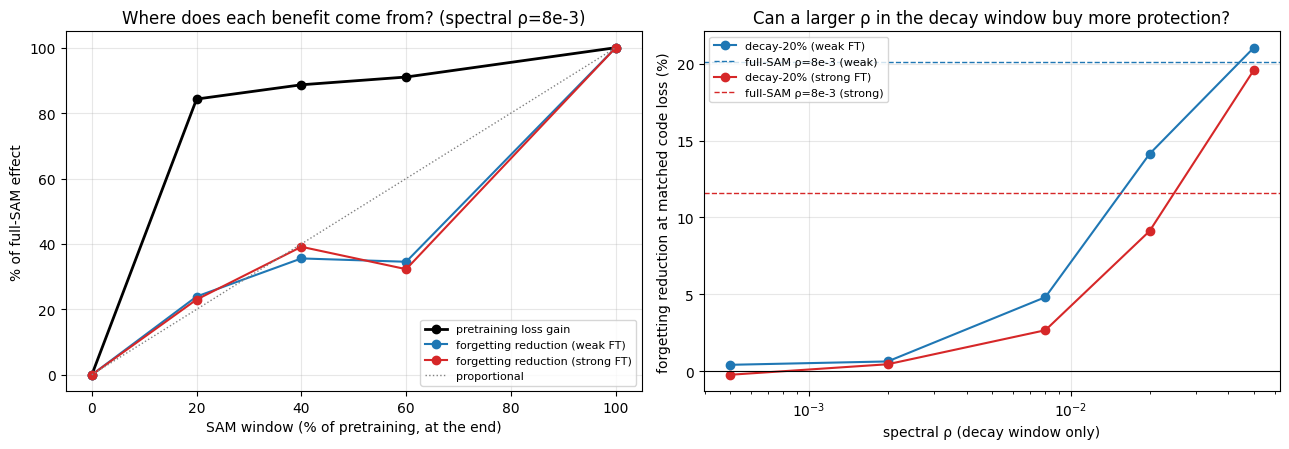

저장: /kaggle/working/exp_l6_finetune


In [6]:
# ============ 셀 6: 결과 — pre_off_repro 대비 망각 감소 + L5B와 합친 곡선 ============
import matplotlib.pyplot as plt
df = pd.DataFrame(ROWS)

TARGET = {}
df['matched_forgetting'] = np.nan
for st in ['weak', 'strong']:
    sub = df[df.strength == st]
    TARGET[st] = max(min(p['code'] for p in CURVES[f'{r.adam_lr}|{r.seed}|{r.pre}']) for r in sub.itertuples())
    for i, r in sub.iterrows():
        df.loc[i, 'matched_forgetting'] = baby_at(CURVES[f'{r.adam_lr}|{r.seed}|{r.pre}'], TARGET[st]) - r.baby_before
df.to_csv(f'{OUT}/ft_results_final.csv', index=False)

print('===== 1. 평균 =====')
display(df.groupby(['strength', 'pre'], sort=False)[['code_after', 'baby_before', 'baby_after', 'forgetting',
                                                    'matched_forgetting', 'delta_rel']].mean().round(4))

print('\n===== 2. pre_off_repro 대비 망각 감소 (같은 seed 짝 비교, 양수 = 덜 잊음) =====')
EFF = []
for st in ['weak', 'strong']:
    print(f'\n[{st}]  같은 코드 loss 기준점 = {TARGET[st]:.3f}')
    a = df[(df.strength == st) & (df.pre == 'pre_off_repro')].set_index('seed').sort_index()
    for pre in MODELS[1:]:
        b = df[(df.strength == st) & (df.pre == pre)].set_index('seed').sort_index()
        d_f = a.forgetting - b.forgetting; d_m = a.matched_forgetting - b.matched_forgetting
        red_f = 1 - b.forgetting.mean() / a.forgetting.mean()
        red_m = 1 - b.matched_forgetting.mean() / a.matched_forgetting.mean()
        cost = PRE_SUM.loc[pre, '비용_배수']
        EFF.append(dict(strength=st, model=pre, cost=cost, red_final=red_f, red_matched=red_m,
                        pos_final=int((d_f > 0).sum()), pos_matched=int((d_m > 0).sum()),
                        code_gain=(a.code_after - b.code_after).mean()))
        print(f'  {SHORT[pre]:18s} 비용 {cost:.2f}배 | 최종 망각 {red_f*100:+5.1f}% ({int((d_f>0).sum())}/3) | '
              f'같은 지점 {red_m*100:+5.1f}% ({int((d_m>0).sum())}/3) | seed별 {[round(x, 4) for x in d_m]} | '
              f'코드 loss 차 {(a.code_after - b.code_after).mean():+.4f}')
eff6 = pd.DataFrame(EFF); eff6.to_csv(f'{OUT}/efficiency.csv', index=False)

# ---------- L5B 결과와 합치기 ----------
try:
    l5 = pd.read_csv(find_input('exp_l5_finetune', 'efficiency.csv'))
except AssertionError as e:
    l5 = None; print('\n※ L5B 결과를 못 찾아서 합친 곡선은 건너뜀:', e)

if l5 is not None:
    def red(tab, st, model):
        return tab[(tab.strength == st) & (tab.model == model)].red_matched.item()
    off6 = PRE_SUM.loc['pre_off_repro', 'babylm_loss']
    PRE_GAIN = {0.0: 0.0, 0.2: 3.3896 - 3.2844, 1.0: 3.3896 - 3.2648,                       # L5A (각자 pre_off 기준)
                0.4: off6 - PRE_SUM.loc['pre_win40_spec_0.008', 'babylm_loss'],          # L6A
                0.6: off6 - PRE_SUM.loc['pre_win60_spec_0.008', 'babylm_loss']}
    print('\n===== 3. SAM 구간 길이 축 (스펙트럼 ρ 0.008): 사전학습 이득 vs 망각 보호, 둘 다 full = 100%로 정규화 =====')
    WIN = {}
    for st in ['weak', 'strong']:
        F_RED = {0.0: 0.0, 0.2: red(l5, st, 'pre_decay_spec_0.008'), 1.0: red(l5, st, 'pre_full_spec'),
                 0.4: red(eff6, st, 'pre_win40_spec_0.008'), 0.6: red(eff6, st, 'pre_win60_spec_0.008')}
        WIN[st] = F_RED
        print(f'\n[{st}]')
        for w in sorted(F_RED):
            print(f'  SAM {int(w*100):3d}% | 사전학습 이득 {PRE_GAIN[w]/PRE_GAIN[1.0]*100:5.1f}% | '
                  f'망각 감소 {F_RED[w]*100:5.1f}% (full 대비 {F_RED[w]/F_RED[1.0]*100:5.1f}%)')

    print('\n===== 4. decay 20% 구간의 ρ 축: 같은 지점 망각 감소 =====')
    RHO = {}
    for st in ['weak', 'strong']:
        RHO[st] = {5e-4: red(l5, st, 'pre_decay_spec_0.0005'), 2e-3: red(l5, st, 'pre_decay_spec_0.002'),
                   8e-3: red(l5, st, 'pre_decay_spec_0.008'), 0.02: red(eff6, st, 'pre_decay_spec_0.02'),
                   0.05: red(eff6, st, 'pre_decay_spec_0.05')}
        full = red(l5, st, 'pre_full_spec')
        print(f'  [{st}] ' + ' | '.join(f'ρ {r:g}: {v*100:+.1f}%' for r, v in RHO[st].items()) + f'   (full 8e-3: {full*100:+.1f}%)')

    # ---------- 헤드라인 그림 ----------
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ws = sorted(PRE_GAIN)
    axes[0].plot([w * 100 for w in ws], [PRE_GAIN[w] / PRE_GAIN[1.0] * 100 for w in ws], 'k-o', lw=2, label='pretraining loss gain')
    for st, c in [('weak', 'tab:blue'), ('strong', 'tab:red')]:
        axes[0].plot([w * 100 for w in ws], [WIN[st][w] / WIN[st][1.0] * 100 for w in ws], '-o', color=c, label=f'forgetting reduction ({st} FT)')
    axes[0].plot([0, 100], [0, 100], ':', color='gray', lw=1, label='proportional')
    axes[0].set_xlabel('SAM window (% of pretraining, at the end)'); axes[0].set_ylabel('% of full-SAM effect')
    axes[0].set_title('Where does each benefit come from? (spectral ρ=8e-3)'); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
    for st, c in [('weak', 'tab:blue'), ('strong', 'tab:red')]:
        rs = sorted(RHO[st])
        axes[1].plot(rs, [RHO[st][r] * 100 for r in rs], '-o', color=c, label=f'decay-20% ({st} FT)')
        axes[1].axhline(red(l5, st, 'pre_full_spec') * 100, color=c, ls='--', lw=1, label=f'full-SAM ρ=8e-3 ({st})')
    axes[1].set_xscale('log'); axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set_xlabel('spectral ρ (decay window only)'); axes[1].set_ylabel('forgetting reduction at matched code loss (%)')
    axes[1].set_title('Can a larger ρ in the decay window buy more protection?'); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{OUT}/headline_window_rho.png', dpi=150); plt.show()
    json.dump(dict(window=WIN, rho=RHO, pre_gain=PRE_GAIN), open(f'{OUT}/summary.json', 'w'), indent=2, default=float)
print('저장:', OUT)